# A4-2 규칙 기반 텍스트 분석: 정보 추출에서 감성 판단, 통계 비교까지

> **4-1 통계 기반(TF-IDF)** 접근과 짝을 이루는 **4-2 규칙 기반 자연어 처리** 구현 요약입니다.  
> 학습된 모델 없이 **정규표현식 + 검증·정규화 코드**로 문장에서 정형 정보를 추출하고, 외부 형태소 분석기(`KoNLPy`) 없이 **순수 파이썬 자모 변이·최장 일치·절 단위 문법 규칙**으로 한국어 문장의 감성을 계산합니다.

| 구성 | 핵심 방법 | 주요 결과 |
| --- | --- | --- |
| **1–2. 정보 추출** | `re.VERBOSE` + 둘러보기 + 코드 검증·정규화 | 80문장(정답 88개) Micro F1 **0.906**, 정규화 **100%** |
| **3–5. 감성 분석** | 자모 확장·어간 변이 매칭 + 절·어절 창 문법 + 확장 4종 | NSMC `test` 1,000건 **76.2%** (자체 사전 **+8.4%p** vs KNU) |
| **6. 규칙 확장** | 개인정보 마스킹(`--mask`) · 속성별 감성(`--aspect`) | 마스킹 오탐 **0건** · 속성별 F1 `0.638 →` **0.921** |
| **7. 통계 비교** | 규칙(4-2) vs 문자 n-gram TF-IDF(4-1) 학습 곡선 | 학습 **3,000건**부터 통계 추월, 결합 시 전 구간 최고(**81.3%**) |

In [1]:
from pathlib import Path
import html
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, Markdown, display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
if not (root / "src" / "sentiment.py").is_file():
    raise FileNotFoundError("A4-2 폴더 또는 notebooks 하위에서 실행해 주세요.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from main import hide_entities
from src import aspect, extract, lexicon, normalize, patterns, sentiment

# 차트 스타일 및 한글 폰트 설정 (현재 OS에 설치된 폰트만 선택해 findfont 경고를 없앤다)
from matplotlib import font_manager
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
for fname in ("Malgun Gothic", "AppleGothic", "NanumGothic", "DejaVu Sans"):
    if fname in available_fonts:
        plt.rcParams["font.family"] = fname
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

OUT_DIR = root / "outputs"
summary_data = json.loads((OUT_DIR / "summary.json").read_text(encoding="utf-8"))
extraction_eval = json.loads((OUT_DIR / "extraction_eval.json").read_text(encoding="utf-8"))
sentiment_eval = json.loads((OUT_DIR / "sentiment_eval.json").read_text(encoding="utf-8"))
masking_eval = json.loads((OUT_DIR / "masking_eval.json").read_text(encoding="utf-8"))
aspect_eval = json.loads((OUT_DIR / "aspect_eval.json").read_text(encoding="utf-8"))
tfidf_eval = json.loads((OUT_DIR / "rule_vs_tfidf.json").read_text(encoding="utf-8"))
lex_stats = json.loads((OUT_DIR / "lexicon_stats.json").read_text(encoding="utf-8"))

analyzer = sentiment.SentimentAnalyzer()
aspect_analyzer = aspect.AspectAnalyzer()

TYPE_COLORS = {
    "email": "#1d63b8",
    "phone": "#d95926",
    "date": "#138a63",
    "money": "#b87a00",
    "url": "#b63b6d",
    "rrn": "#0b6e26",
    "card": "#5441b5",
    "address": "#c93737",
}

def show_table(headers, rows):
    lines = [" | ".join(headers), " | ".join(["---"] * len(headers))]
    for row in rows:
        lines.append(" | ".join(str(v).replace("|", "/") for v in row))
    display(Markdown("\n".join(lines)))

def render_entities_html(text, ents, title="추출 결과 하이라이트"):
    chunks, last = [], 0
    for e in sorted(ents, key=lambda x: x.start):
        chunks.append(html.escape(text[last:e.start]))
        color = TYPE_COLORS.get(e.type, "#495057")
        label = patterns.LABELS.get(e.type, e.type)
        val = html.escape(str(e.value))
        chunks.append(
            f"<span style='display:inline-block;background:{color}18;border:1px solid {color};"
            f"color:#1f2328;border-radius:6px;padding:1px 6px;margin:1px 2px;'>"
            f"<b style='color:{color};font-size:11px;'>[{label}]</b> {html.escape(e.text)}"
            f"<span style='color:#57606a;font-size:11px;'> → {val}</span></span>"
        )
        last = e.end
    chunks.append(html.escape(text[last:]))
    return (
        f"<div style='background:#f8f9fa;border:1px solid #dee2e6;border-radius:10px;"
        f"padding:12px 14px;color:#1f2328;line-height:1.8;font-size:14px;margin:6px 0;'>"
        f"<div style='font-size:12px;font-weight:700;color:#57606a;margin-bottom:4px;'>{html.escape(title)}</div>"
        f"{''.join(chunks)}</div>"
    )

def render_sentiment_card(res, title="감성 점수 계산"):
    chips = []
    for item in res.items:
        color = "#1d63b8" if item.value > 0 else ("#c93737" if item.value < 0 else "#6e7781")
        detail = [f"{item.base:+g}"]
        if item.negators:
            detail.append(f"부정({','.join(item.negators)} ×{item.negation_factor:+g})")
        if item.modifiers:
            detail.append(" ".join(f"{s}×{f:g}" for s, f in item.modifiers))
        if item.contrast != 1.0:
            detail.append(f"대조×{item.contrast:g}")
        chips.append(
            f"<span style='display:inline-block;background:{color}14;border:1px solid {color};"
            f"color:#1f2328;border-radius:6px;padding:2px 8px;margin:2px 4px 2px 0;font-size:13px;'>"
            f"<b>{html.escape(item.surface)}</b> ({' · '.join(detail)}) = <b style='color:{color};'>{item.value:+g}</b></span>"
        )
    for o in res.orphans:
        chips.append(
            f"<span style='display:inline-block;background:#c9373714;border:1px solid #c93737;"
            f"color:#1f2328;border-radius:6px;padding:2px 8px;margin:2px 4px 2px 0;font-size:13px;'>"
            f"<b>고립 부정({html.escape(o['surface'])})</b> = <b style='color:#c93737;'>{o['value']:+g}</b></span>"
        )
    if res.rating:
        r = res.rating
        c = "#1d63b8" if r["value"] > 0 else "#c93737"
        chips.append(
            f"<span style='display:inline-block;background:{c}14;border:1px solid {c};"
            f"color:#1f2328;border-radius:6px;padding:2px 8px;margin:2px 4px 2px 0;font-size:13px;'>"
            f"<b>평점({html.escape(r['text'])})</b> = <b style='color:{c};'>{r['value']:+g}</b></span>"
        )
    if not chips:
        chips.append("<span style='color:#57606a;font-size:13px;'>탐지된 감성 단서 없음 (0점 기본값 적용)</span>")
    v_color = "#1d63b8" if res.label == 1 else "#c93737"
    v_text = "긍정" if res.label == 1 else "부정"
    tie_note = " (0점 기본값)" if res.decided_by_tie else ""
    return (
        f"<div style='background:#f8f9fa;border:1px solid #dee2e6;border-radius:10px;"
        f"padding:12px 14px;color:#1f2328;line-height:1.7;font-size:14px;margin:6px 0;'>"
        f"<div style='display:flex;justify-content:space-between;align-items:center;margin-bottom:6px;'>"
        f"<span style='font-size:12px;font-weight:700;color:#57606a;'>{html.escape(title)}</span>"
        f"<span style='background:{v_color};color:#ffffff;border-radius:999px;padding:2px 10px;font-size:12px;font-weight:700;'>"
        f"{v_text} ({res.score:+g}){tie_note}</span></div>"
        f"<div>{''.join(chips)}</div></div>"
    )

print(f"환경 준비 완료 · 자체 감성 사전 {lex_stats['custom_entries']}개(수식어 {lex_stats['modifiers']}개 별도) · Python {sys.version.split()[0]}")

환경 준비 완료 · 자체 감성 사전 412개(수식어 54개 별도) · Python 3.12.13


## 1. 한눈에 보는 End-to-End 파이프라인

정보 추출(`extract`)과 감성 분석(`sentiment`)은 목적과 평가 지표가 달라 독립 모듈로 설계하고, 연결 지점에서는 추출된 개체를 자리표시자(`□`)로 치환(`hide_entities`)해 넘깁니다.  
이 전처리 덕분에 날짜 숫자나 이메일 도메인 영어가 감성 규칙(평점 언급·영문 감성어)에 간섭하지 않으며, `2023년 2월 29일`처럼 존재하지 않는 날짜는 추출 단계에서 걸러집니다.

In [2]:
sample_inquiry = "문의: demo@example.com, 전화 010-0000-0001, 예약 2024년 3월 15일, 변경 2023년 2월 29일, 참가비 5만원. 정말 맛있지 않았어요"

ents = extract.extract(sample_inquiry)
masked_for_senti = hide_entities(sample_inquiry, ents)
senti_res = analyzer.analyze(masked_for_senti, sentiment.FINAL_CONFIG)

card_masked = (
    f"<div style='background:#f8f9fa;border:1px solid #dee2e6;border-radius:10px;"
    f"padding:10px 14px;color:#1f2328;font-size:14px;margin:6px 0;'>"
    f"<div style='font-size:12px;font-weight:700;color:#57606a;margin-bottom:2px;'>개체 치환 후 감성 분석 입력 (hide_entities)</div>"
    f"<code>{html.escape(masked_for_senti)}</code></div>"
)
display(HTML(render_entities_html(sample_inquiry, ents, "1단계 · 정보 추출 및 정규화 (2023-02-29는 달력 검증 탈락)") + card_masked + render_sentiment_card(senti_res, "2단계 · 규칙 기반 감성 계산")))

## 2. 정보 추출: 정규식과 코드 검증의 역할 분담

정규표현식은 **후보 탐색**에 집중하고, **의미 검증과 형식 통일**은 파이썬 코드([src/normalize.py](../src/normalize.py))가 맡습니다.

- **유니코드 경계 문제 회피:** `\d`, `\b` 대신 `[0-9]`, `[A-Za-z]`를 명시해 한글 조사 바로 앞(`support@example.com입니다`)에서도 정확히 끊어 냅니다.
- **둘러보기(`(?<!...)` / `(?!...)`):** 주문번호 같은 긴 숫자열의 일부를 전화번호·날짜로 잘라 오는 오탐을 막습니다.
- **역참조(`(?P=sep)`)와 윤년 검증:** `2024-01/15`처럼 구분자를 섞은 표기는 패턴 역참조로 막고, `2월 29일` 유무는 `datetime.date`로 걸러 패턴 가독성을 지킵니다.

In [3]:
cases = [
    ("날짜", ["2024년 3월 15일", "2024/03/15", "24.3.15", "March 15, 2024", "2023년 2월 29일"]),
    ("전화번호", ["010-0000-0001", "01000000001", "+82 10-0000-0001", "1588-0001"]),
    ("금액", ["5만원", "1억 2천만원", "₩10,000", "$1,299.99"]),
]
rows = []
for label, texts in cases:
    for t in texts:
        found = extract.extract(t)
        if found:
            e = found[0]
            rows.append([label, t, e.type, str(e.value), e.info or "-"])
        else:
            rows.append([label, t, "-", "탈락 (유효하지 않음)", "-"])

show_table(["유형", "원문 표기", "판정 타입", "정규화 결과", "부가 정보"], rows)
print("[참고] src/patterns.py DATE 패턴 일부:")
print("\n".join(patterns.DATE.strip().splitlines()[:15]))

[참고] src/patterns.py DATE 패턴 일부:
(?<![0-9])                            # 앞이 숫자면 더 긴 숫자열의 일부다
(?:                                   # 세 가지 표기 중 하나
  (?:(?P<y>[0-9]{4}|[0-9]{2})년[ ]?)? # (1) 한국어 표기. 연도는 생략 가능 ("3월 15일"), 2자리 연도 허용 ("24년")
  (?P<m>[0-9]{1,2})월[ ]?             #     월 1~2자리
  (?P<d>[0-9]{1,2})일                 #     일 1~2자리
 |
  (?P<y2>[0-9]{4}|[0-9]{2})           # (2) 숫자 + 구분자 표기: 2024-01-15, 2024/01/15, 2024.01.15, 24.1.15
  (?P<sep>[./-])[ ]?                  #     첫 구분자를 그룹으로 잡아 두고
  (?P<m2>[0-9]{1,2})                 #     월 1~2자리 (13월 같은 값은 normalize가 거른다)
  (?P=sep)[ ]?                        #     역참조로 같은 구분자만 허용 (2024-01/15 같은 혼합 거부)
  (?P<d2>[0-9]{1,2})                 #     일 1~2자리
  (?![0-9]|[.][0-9])                  #     뒤에 숫자나 ".숫자"가 오면 버전 번호(1.2.3.4) 같은 것이다
  [.]?                                #     "2024. 3. 15."의 마지막 점
 |
  (?P<mon>Jan(?:uary)?|Feb(?:ruary)?|Mar(?:ch)?|Apr(?:il)?|May|June?|July?|Aug(?:ust)?|Sep(?:t(?:ember)?)?|Oct(?:ober)?|Nov(?:ember)

유형 | 원문 표기 | 판정 타입 | 정규화 결과 | 부가 정보
--- | --- | --- | --- | ---
날짜 | 2024년 3월 15일 | date | 2024-03-15 | -
날짜 | 2024/03/15 | date | 2024-03-15 | -
날짜 | 24.3.15 | date | 2024-03-15 | -
날짜 | March 15, 2024 | date | 2024-03-15 | -
날짜 | 2023년 2월 29일 | - | 탈락 (유효하지 않음) | -
전화번호 | 010-0000-0001 | phone | 010-0000-0001 | {'kind': '휴대전화'}
전화번호 | 01000000001 | phone | 010-0000-0001 | {'kind': '휴대전화'}
전화번호 | +82 10-0000-0001 | phone | 010-0000-0001 | {'kind': '휴대전화'}
전화번호 | 1588-0001 | phone | 1588-0001 | {'kind': '대표번호'}
금액 | 5만원 | money | 50000 | {'currency': 'KRW'}
금액 | 1억 2천만원 | money | 120000000 | {'currency': 'KRW'}
금액 | ₩10,000 | money | 10000 | {'currency': 'KRW'}
금액 | $1,299.99 | money | 129999 | {'currency': 'USD', 'unit': 'cent'}

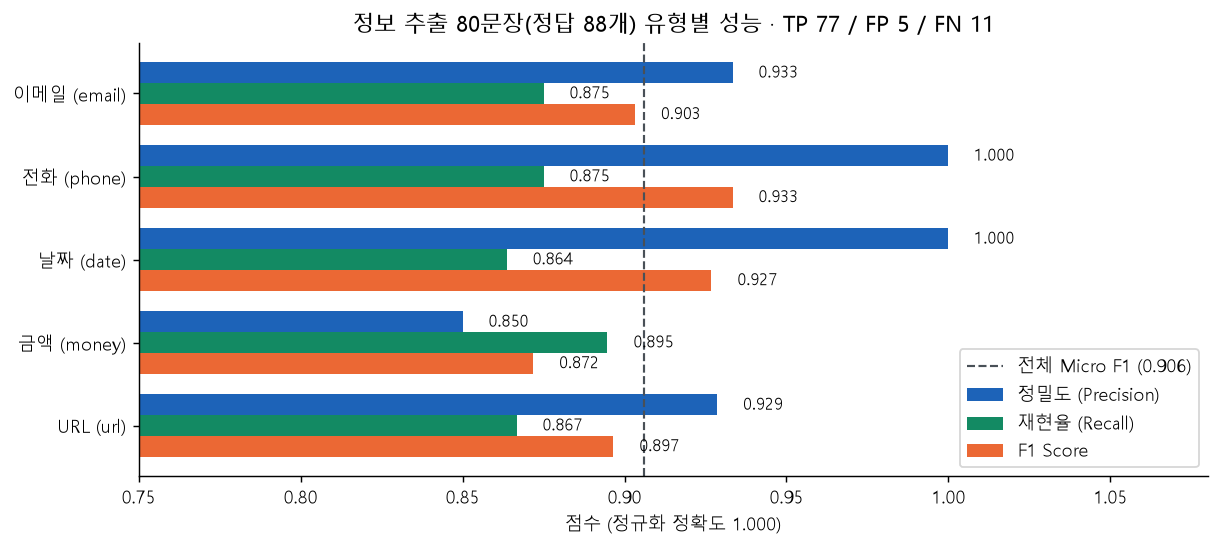

In [4]:
per_type = extraction_eval["per_type"]
micro = extraction_eval["micro"]
types_order = ["email", "phone", "date", "money", "url"]
type_labels = [f"{patterns.LABELS[t]} ({t})" for t in types_order]

precisions = [per_type[t]["precision"] for t in types_order]
recalls = [per_type[t]["recall"] for t in types_order]
f1s = [per_type[t]["f1"] for t in types_order]

y = np.arange(len(types_order))
h = 0.25

fig, ax = plt.subplots(figsize=(9.5, 4.3))
b1 = ax.barh(y - h, precisions, height=h, color="#1d63b8", label="정밀도 (Precision)")
b2 = ax.barh(y, recalls, height=h, color="#138a63", label="재현율 (Recall)")
b3 = ax.barh(y + h, f1s, height=h, color="#eb6834", label="F1 Score")

for bars in (b1, b2, b3):
    for bar in bars:
        w = bar.get_width()
        ax.text(w + 0.008, bar.get_y() + bar.get_height() / 2, f"{w:.3f}", va="center", fontsize=9)

ax.axvline(micro["f1"], color="#495057", linestyle="--", linewidth=1.2, label=f"전체 Micro F1 ({micro['f1']:.3f})")
ax.set_yticks(y, type_labels)
ax.invert_yaxis()
ax.set_xlim(0.75, 1.08)
ax.set_xlabel("점수 (정규화 정확도 1.000)")
ax.set_title(f"정보 추출 80문장(정답 88개) 유형별 성능 · TP {micro['tp']} / FP {micro['fp']} / FN {micro['fn']}")
ax.legend(loc="lower right", frameon=True)
fig.tight_layout()
plt.show()

## 3. 형태소 분석기 없는 한국어 활용 매칭

이 구현은 `KoNLPy` 같은 외부 형태소 분석기 없이 [src/lexicon.py](../src/lexicon.py)의 순수 파이썬 유니코드 자모 분해(`0xAC00–0xD7A3`)만으로 용언 활용형을 다룹니다.

1. **어간 활용 변이(`predicate_variants`):** `하→해`, 모음 축약(`ㅣ→ㅕ`), `ㅂ·르·ㅅ` 불규칙 형태를 사전 로딩 시 자동 생성합니다.
2. **받침 확장(`ext`):** 어간 마지막 음절에 받침이 없으면 종성이 붙은 음절(`지루하 → 지루한·지루할·지루함`)까지 함께 일치시킵니다.
3. **최장 일치 & 정확 일치 우선:** 위치마다 가장 긴 표제어를 고르고(`재미없 > 재미`), 길이가 같으면 받침 확장 없는 정확 일치가 우선합니다.

In [5]:
variant_rows = []
for stem, rule_desc in [
    ("지루하", "하→해 축약 + 받침 확장"),
    ("멋지", "ㅣ→ㅕ 모음 축약"),
    ("아깝", "ㅂ 불규칙(우/워) 전개"),
    ("다르", "르 불규칙(달라) 전개"),
]:
    variant_rows.append([stem, rule_desc, ", ".join(lexicon.predicate_variants(stem))])
show_table(["어간(사전 등록)", "적용 규칙", "자동 생성된 표면형(받침 확장 전)"], variant_rows)

demo_sentence = "지루한 영화였지만 초반은 지루했어요. 시간이 아까워요. 그래도 재미없지는 않다"
hits = analyzer.matcher.find(demo_sentence)
hit_rows = [
    [h.surface, h.entry.term, h.kind, f"{h.entry.score:+g}", "정확 일치" if h.exact else "받침 확장"]
    for h in hits
]
print(f'예문: "{demo_sentence}"')
show_table(["문장에서 잡힌 표면형", "원 표제어", "역할", "점수/배율", "매칭 방식"], hit_rows)

예문: "지루한 영화였지만 초반은 지루했어요. 시간이 아까워요. 그래도 재미없지는 않다"


어간(사전 등록) | 적용 규칙 | 자동 생성된 표면형(받침 확장 전)
--- | --- | ---
지루하 | 하→해 축약 + 받침 확장 | 지루하, 지루해
멋지 | ㅣ→ㅕ 모음 축약 | 멋지, 멋져
아깝 | ㅂ 불규칙(우/워) 전개 | 아깝, 아까우, 아까워
다르 | 르 불규칙(달라) 전개 | 다르, 달라

문장에서 잡힌 표면형 | 원 표제어 | 역할 | 점수/배율 | 매칭 방식
--- | --- | --- | --- | ---
지루한 | 지루하 | SENTI | -2 | 받침 확장
지루했 | 지루하 | SENTI | -2 | 받침 확장
아까워 | 아깝 | SENTI | -2 | 정확 일치
재미없 | 재미없 | SENTI | -2 | 정확 일치
않 | 않 | NEG_POST | -1 | 정확 일치

## 4. 감성 규칙의 작동과 단계별 성능 변화

감성 분석([src/sentiment.py](../src/sentiment.py))은 **절 경계**와 **어절 거리 창** 안에서 작동합니다.  
규칙 튜닝은 NSMC `dev`(1,000건)에서만 확인해 설정(`FINAL_CONFIG`)을 고정했고, `test`(1,000건)는 최종 검증에만 사용했습니다.

In [6]:
rule_examples = [
    ("부정어 반전", "좋지 않다"),
    ("강조어 가중", "매우 좋다"),
    ("부정 + 강조 동시", "정말 맛있지 않았어요"),
    ("최장 일치 + 부정", "영화가 재미없는 건 아니야"),
    ("이중부정 복원", "재미있지 않을 수 없다"),
    ("대조 접속 가중", "초반은 지루했지만 결말이 정말 좋았다"),
]

cfg_a = sentiment.Config(negation=False, intensifier=False, double_negation=False)
cfg_e = sentiment.REQUIRED_CONFIG
cfg_i = sentiment.FINAL_CONFIG

def fmt_res(r):
    tag = "긍정" if r.label == 1 else "부정"
    return f"{tag} ({r.score:+g})"

comp_rows = []
for kind, txt in rule_examples:
    ra = analyzer.analyze(txt, cfg_a)
    re_ = analyzer.analyze(txt, cfg_e)
    ri = analyzer.analyze(txt, cfg_i)
    comp_rows.append([kind, txt, fmt_res(ra), fmt_res(re_), fmt_res(ri)])

show_table(["규칙 확인 항목", "예문", "A. 사전 합산만", "E. 필수 규칙(부정·강조·이중)", "I. 최종 확장(+이모·대조·고립·평점)"], comp_rows)

규칙 확인 항목 | 예문 | A. 사전 합산만 | E. 필수 규칙(부정·강조·이중) | I. 최종 확장(+이모·대조·고립·평점)
--- | --- | --- | --- | ---
부정어 반전 | 좋지 않다 | 긍정 (+2) | 부정 (-2) | 부정 (-2)
강조어 가중 | 매우 좋다 | 긍정 (+2) | 긍정 (+3) | 긍정 (+3)
부정 + 강조 동시 | 정말 맛있지 않았어요 | 긍정 (+2) | 부정 (-3) | 부정 (-3)
최장 일치 + 부정 | 영화가 재미없는 건 아니야 | 부정 (-2) | 긍정 (+2) | 긍정 (+2)
이중부정 복원 | 재미있지 않을 수 없다 | 긍정 (+2) | 긍정 (+2) | 긍정 (+2)
대조 접속 가중 | 초반은 지루했지만 결말이 정말 좋았다 | 부정 (+0) | 긍정 (+1) | 긍정 (+3.5)

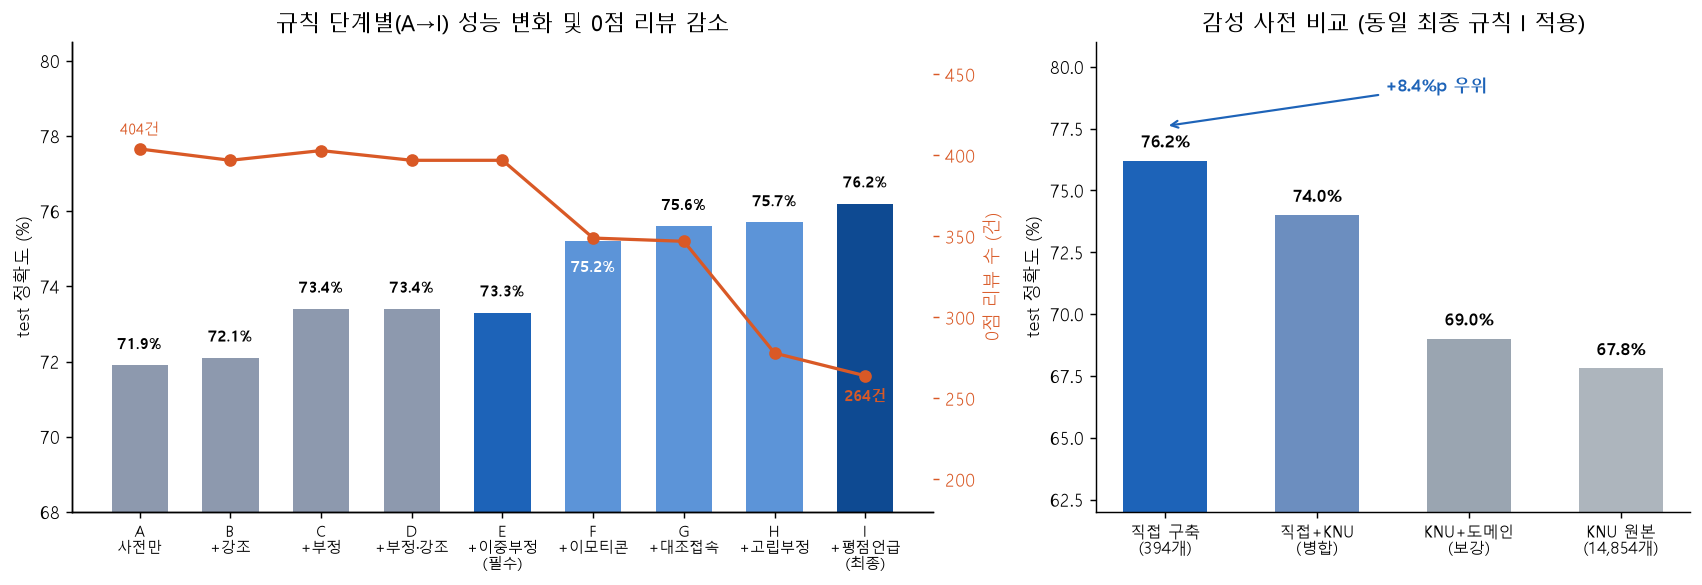

In [7]:
ablation = sentiment_eval["test"]["ablation"]
short_labels = [
    "A\n사전만", "B\n+강조", "C\n+부정", "D\n+부정·강조",
    "E\n+이중부정\n(필수)", "F\n+이모티콘", "G\n+대조접속", "H\n+고립부정", "I\n+평점언급\n(최종)"
]
accs = [x["accuracy"] * 100 for x in ablation]
ties = [x["ties"] for x in ablation]

lex_test = [x for x in sentiment_eval["lexicon_comparison"]["test"] if x["config"] == "최종(I)"]
lex_names_map = {
    "custom": "직접 구축\n(394개)",
    "union": "직접+KNU\n(병합)",
    "knu+domain": "KNU+도메인\n(보강)",
    "knu": "KNU 원본\n(14,854개)",
}
lex_order = ["custom", "union", "knu+domain", "knu"]
lex_by_name = {x["lexicon"]: x for x in lex_test}
lex_accs = [lex_by_name[k]["accuracy"] * 100 for k in lex_order]
lex_labels = [lex_names_map[k] for k in lex_order]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.2, 4.6), gridspec_kw={"width_ratios": [1.45, 1.0]})

x1 = np.arange(len(short_labels))
bar_colors = ["#8d99ae"] * 4 + ["#1d63b8"] + ["#5c94d8"] * 3 + ["#0e4a92"]
bars1 = ax1.bar(x1, accs, color=bar_colors, width=0.62)
for b, v in zip(bars1, accs):
    y_pos = v - 0.9 if abs(v - 75.2) < 0.05 else v + 0.35
    txt_color = "#ffffff" if abs(v - 75.2) < 0.05 else "#000000"
    ax1.text(b.get_x() + b.get_width() / 2, y_pos, f"{v:.1f}%", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color=txt_color)
ax1.set_xticks(x1, short_labels, fontsize=8.5)
ax1.set_ylim(68, 80.5)
ax1.set_ylabel("test 정확도 (%)")
ax1.set_title("규칙 단계별(A→I) 성능 변화 및 0점 리뷰 감소")

ax1_r = ax1.twinx()
ax1_r.spines["top"].set_visible(False)
ax1_r.plot(x1, ties, color="#d95926", marker="o", linewidth=1.8, label="0점(단서 부재) 건수")
ax1_r.set_ylim(180, 470)
ax1_r.set_ylabel("0점 리뷰 수 (건)", color="#d95926")
ax1_r.tick_params(axis="y", colors="#d95926")
ax1_r.annotate("404건", (0, ties[0]), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8.5, color="#d95926")
ax1_r.annotate("264건", (8, ties[8]), xytext=(0, -14), textcoords="offset points", ha="center", fontsize=8.5, color="#d95926", fontweight="bold")

x2 = np.arange(len(lex_labels))
c2 = ["#1d63b8", "#6c8ebf", "#9aa5b1", "#adb5bd"]
bars2 = ax2.bar(x2, lex_accs, color=c2, width=0.55)
for b, v in zip(bars2, lex_accs):
    ax2.text(b.get_x() + b.get_width() / 2, v + 0.4, f"{v:.1f}%", ha="center", va="bottom", fontsize=9.5, fontweight="bold")
ax2.set_xticks(x2, lex_labels, fontsize=9)
ax2.set_ylim(62, 81)
ax2.set_ylabel("test 정확도 (%)")
ax2.set_title("감성 사전 비교 (동일 최종 규칙 I 적용)")
ax2.annotate("+8.4%p 우위", xy=(0, lex_accs[0] + 1.4), xytext=(1.45, 79.0),
             arrowprops=dict(arrowstyle="->", color="#1d63b8", lw=1.2), fontsize=9.5, fontweight="bold", color="#1d63b8")

fig.tight_layout()
plt.show()

> **숫자 해석 포인트:** 전체 `test` 정확도(A `71.9%` → E `73.3%`) 차이가 작아 보이지만, 부정어가 실제로 작동한 `test` 72건만 따로 재면 **`50.0% → 68.1%`**로 뚜렷하게 오릅니다. 또한 37배 큰 `KNU` 사전(14,854개)보다 도메인에 맞춘 직접 구축 사전(394개)이 `+8.4%p` 높게 나와, 감성 사전은 **크기보다 도메인 적합성**이 중요함을 확인할 수 있습니다.

## 5. 규칙의 한계와 주요 오분류 유형

`test` 1,000건 중 오분류는 총 **238건**이며, 이 중 **120건(50.4%)**은 사전에 등록된 단서가 전혀 없어 0점 기본값(부정)으로 떨어진 긍정 리뷰입니다. 나머지는 문맥을 보지 못하는 문자열 규칙 특유의 오류입니다.

In [8]:
err_cases = [
    ("동음이의(추출)", "만원 버스", "부정(0) / 10,000원 추출", "문맥 없이 '만원'을 금액 10,000원으로 오인"),
    ("부분 문자열 오탐", "참된 평화와 회복을 소망합니다", "긍정(1)", "형태소 경계 없이 '소망합' 안의 '망합(망하다)'을 -2로 매칭"),
    ("관용적 부정", "결코 잊을 수 없는 영화", "긍정(1)", "'잊을 수 없다'는 찬사인데 '없'이 고립 부정(-1)으로 작동"),
    ("반어 · 비꼼", "눈물짜내기의 끝판왕.", "부정(0)", "신파를 비꼬는 '눈물(+1)'과 '끝판왕(+2)'을 문자 그대로 합산"),
    ("단서 부재 + 고립 부정", "문제가 없어요", "긍정(1)", "'문제'가 사전에 없어 '없'(-1)만 남아 부정으로 역전"),
]

err_rows = []
for err_type, txt, gold, cause in err_cases:
    ents_e = extract.extract(txt)
    res_e = analyzer.analyze(hide_entities(txt, ents_e), sentiment.FINAL_CONFIG)
    if ents_e:
        pred_desc = f"추출: {ents_e[0].type}={ents_e[0].value}"
    else:
        pred_desc = f"{'긍정' if res_e.label == 1 else '부정'} ({res_e.score:+g})"
    err_rows.append([err_type, txt, gold, pred_desc, cause])

show_table(["오류 유형", "입력 문장", "실제 정답", "규칙 출력", "발생 원인"], err_rows)

오류 유형 | 입력 문장 | 실제 정답 | 규칙 출력 | 발생 원인
--- | --- | --- | --- | ---
동음이의(추출) | 만원 버스 | 부정(0) / 10,000원 추출 | 추출: money=10000 | 문맥 없이 '만원'을 금액 10,000원으로 오인
부분 문자열 오탐 | 참된 평화와 회복을 소망합니다 | 긍정(1) | 부정 (-2) | 형태소 경계 없이 '소망합' 안의 '망합(망하다)'을 -2로 매칭
관용적 부정 | 결코 잊을 수 없는 영화 | 긍정(1) | 부정 (-1) | '잊을 수 없다'는 찬사인데 '없'이 고립 부정(-1)으로 작동
반어 · 비꼼 | 눈물짜내기의 끝판왕. | 부정(0) | 긍정 (+3) | 신파를 비꼬는 '눈물(+1)'과 '끝판왕(+2)'을 문자 그대로 합산
단서 부재 + 고립 부정 | 문제가 없어요 | 긍정(1) | 부정 (-1) | '문제'가 사전에 없어 '없'(-1)만 남아 부정으로 역전

## 6. 규칙의 확장: 개인정보 마스킹 & 속성별 감성 분석

동일한 정규식·절 분석 인프라를 두 가지 실용 과제로 확장했습니다.

1. **개인정보 마스킹(`--mask`):** 같은 추출 엔진에 주민번호(`rrn`)·카드(`card`)·주소(`address`) 패턴과 Luhn 검증을 추가했습니다.
2. **속성별 감성 분석(`--aspect`):** 단일 점수 모델에서 `"음식은 맛있는데 가격이 비싸요"`가 `(+2) + (-2) = 0점`으로 상쇄되는 문제를, **대조 절 분리 + 앞 속성 우선 연결(`preceding`) + 문맥 의존어(`짜다`→맛 부정)**로 해결합니다.

In [9]:
mask_input = "배송지: 서울시 강남구 예시로 123, 연락처 010-0000-0001, 주민번호 900101-1234567, 카드 4012-8888-8888-1881, hong@example.com"
masked_text, masked_ents = extract.mask(mask_input)

mask_html = f"""
<div style='background:#f8f9fa;border:1px solid #dee2e6;border-radius:10px;padding:12px 14px;color:#1f2328;font-size:14px;line-height:1.8;'>
  <div style='font-size:12px;font-weight:700;color:#57606a;margin-bottom:4px;'>개인정보 마스킹 실시간 결과 (20문장 평가: 오탐 0건 · 유출 3건 · 유출률 {masking_eval['leak_rate']*100:.0f}%)</div>
  <div><b>원문:</b> {html.escape(mask_input)}</div>
  <div><b>결과:</b> <span style='color:#0e4a92;font-weight:600;'>{html.escape(masked_text)}</span></div>
</div>
"""
display(HTML(mask_html))

leak_rows = [[lk["type"], lk["text"], row["fail"]] for lk in masking_eval["leaks"] for row in masking_eval["rows"] if row["id"] == lk["id"]]
show_table(["유출(미탐) 유형", "놓친 사례", "원인 (마스킹은 정밀도보다 재현율이 핵심)"], leak_rows)

유출(미탐) 유형 | 놓친 사례 | 원인 (마스킹은 정밀도보다 재현율이 핵심)
--- | --- | ---
rrn | 9001011234567 | 구분자 없는 표기
address | 강남구 예시로 123 | 시·도 생략
phone | 공일공 공공공공 공공공일 | 한글 숫자 표기

In [10]:
aspect_samples = [
    "음식은 맛있는데 가격이 비싸요",
    "배송은 빨랐는데 상품에 하자가 있었어요",
    "가격 대비 품질은 괜찮은데 배송이 너무 느려요",
]

aspect_rows = []
for txt in aspect_samples:
    whole = analyzer.analyze(txt, sentiment.FINAL_CONFIG)
    asp_res = aspect_analyzer.analyze(txt)
    whole_str = f"{'긍정' if whole.label == 1 else '부정'} ({whole.score:+g})"
    asp_str = ", ".join(
        f"{k}: {'긍정' if v['polarity'] == 'pos' else '부정'}({v['score']:+g})"
        for k, v in asp_res.aspects.items()
    )
    aspect_rows.append([txt, whole_str, asp_str])

show_table(["복합 평가 문장", "문장 전체 단일 판정", "속성별 분리 판정 (--aspect)"], aspect_rows)
print(
    f"48문장 속성-극성 쌍 평가: 문장 전체 기준 F1 {aspect_eval['preceding']['sentence_baseline']['f1']:.3f}"
    f" → 속성별 분리 F1 {aspect_eval['preceding']['pair']['f1']:.3f}"
    f" (Precision {aspect_eval['preceding']['pair']['precision']:.3f}, Recall {aspect_eval['preceding']['pair']['recall']:.3f})"
)

48문장 속성-극성 쌍 평가: 문장 전체 기준 F1 0.638 → 속성별 분리 F1 0.921 (Precision 0.970, Recall 0.877)


복합 평가 문장 | 문장 전체 단일 판정 | 속성별 분리 판정 (--aspect)
--- | --- | ---
음식은 맛있는데 가격이 비싸요 | 부정 (+0) | 맛: 긍정(+2), 가격: 부정(-2)
배송은 빨랐는데 상품에 하자가 있었어요 | 부정 (-2) | 배송: 긍정(+2), 품질: 부정(-2)
가격 대비 품질은 괜찮은데 배송이 너무 느려요 | 부정 (-0.5) | 품질: 긍정(+1), 배송: 부정(-3)

## 7. 결론: 규칙 기반(4-2) vs 통계 기반(4-1, TF-IDF)

동일한 NSMC `test` 1,000건 위에서 학습 리뷰 수(10–10,000건)를 늘려 가며 문자 n-gram(`char_wb`, 1–3) TF-IDF + 로지스틱 회귀와 비교했습니다.

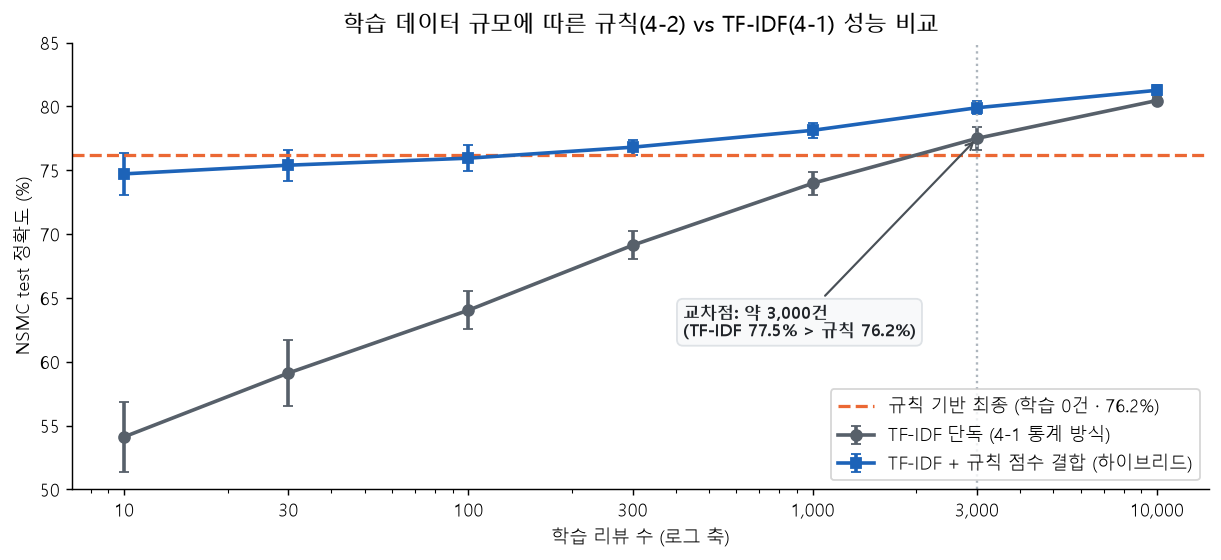

상황 | 적합한 접근 | 실측 근거
--- | --- | ---
이메일·전화·날짜·카드 등 정형 패턴 추출 | 규칙 | 구문 패턴을 직접 정의 가능 (정밀도 0.939 · 정규화 100%)
라벨 데이터가 거의 없거나 즉각 설명이 필요할 때 | 규칙 | 학습 10건일 때 TF-IDF 54.1% vs 규칙 76.2%, 계산식 직접 설명
수천 건 이상의 라벨 데이터 · 다양한 구어 표현 | 통계(ML) | 약 3,000건부터 TF-IDF(77.5%)가 규칙을 추월, 10,000건 80.5%
도메인 규칙과 학습 데이터가 모두 있을 때 | 규칙 + 통계 결합 | 전 구간에서 TF-IDF 단독 대비 우위 (10건 74.7% · 10,000건 81.3%)

In [11]:
curve = tfidf_eval["curve"]
rule_acc = summary_data["sentiment_test"]["I H + 평점 언급"]

fig, ax = plt.subplots(figsize=(9.5, 4.4))
styles = [
    ("TF-IDF", "TF-IDF 단독 (4-1 통계 방식)", "#57606a", "o", "-"),
    ("TF-IDF+규칙 점수", "TF-IDF + 규칙 점수 결합 (하이브리드)", "#1d63b8", "s", "-"),
]
for model_key, label, color, marker, ls in styles:
    rows_m = [r for r in curve if r["model"] == model_key]
    ns = [r["n"] for r in rows_m]
    means = [r["acc_mean"] * 100 for r in rows_m]
    stds = [r["acc_std"] * 100 for r in rows_m]
    ax.errorbar(ns, means, yerr=stds, marker=marker, linestyle=ls, color=color, capsize=3, linewidth=2, label=label)

ax.axhline(rule_acc * 100, color="#eb6834", linestyle="--", linewidth=1.8, label=f"규칙 기반 최종 (학습 0건 · {rule_acc*100:.1f}%)")
ax.axvline(tfidf_eval["crossover_n"], color="#adb5bd", linestyle=":", linewidth=1.3)
ax.annotate("교차점: 약 3,000건\n(TF-IDF 77.5% > 규칙 76.2%)",
            xy=(3000, 77.5), xytext=(420, 62),
            arrowprops=dict(arrowstyle="->", color="#495057", lw=1.2),
            fontsize=9.5, fontweight="bold", color="#1f2328",
            bbox=dict(boxstyle="round,pad=0.35", facecolor="#f8f9fa", edgecolor="#dee2e6"))

ax.set_xscale("log")
ax.set_xticks(tfidf_eval["sizes"], [f"{n:,}" for n in tfidf_eval["sizes"]])
ax.set_ylim(50, 85)
ax.set_xlabel("학습 리뷰 수 (로그 축)")
ax.set_ylabel("NSMC test 정확도 (%)")
ax.set_title("학습 데이터 규모에 따른 규칙(4-2) vs TF-IDF(4-1) 성능 비교")
ax.legend(loc="lower right", frameon=True)
fig.tight_layout()
plt.show()

decision_rows = [
    ["이메일·전화·날짜·카드 등 정형 패턴 추출", "규칙", "구문 패턴을 직접 정의 가능 (정밀도 0.939 · 정규화 100%)"],
    ["라벨 데이터가 거의 없거나 즉각 설명이 필요할 때", "규칙", "학습 10건일 때 TF-IDF 54.1% vs 규칙 76.2%, 계산식 직접 설명"],
    ["수천 건 이상의 라벨 데이터 · 다양한 구어 표현", "통계(ML)", "약 3,000건부터 TF-IDF(77.5%)가 규칙을 추월, 10,000건 80.5%"],
    ["도메인 규칙과 학습 데이터가 모두 있을 때", "규칙 + 통계 결합", "전 구간에서 TF-IDF 단독 대비 우위 (10건 74.7% · 10,000건 81.3%)"],
]
show_table(["상황", "적합한 접근", "실측 근거"], decision_rows)

## 8. 직접 문장 분석해 보기

아래 `sample_text`만 바꿔 실행하면 개체 추출, 개인정보 마스킹, 문장 감성 계산, 속성별 감성 분리 결과를 한 번에 확인할 수 있습니다.

In [12]:
sample_text = "문의: demo@example.com, 연락처 010-0000-0001, 예약 2024년 3월 15일. 음식은 정말 맛있는데 가격이 너무 비싸요"

ents_u = extract.extract(sample_text)
masked_u, _ = extract.mask(sample_text)
plain_u = hide_entities(sample_text, ents_u)
res_u = analyzer.analyze(plain_u, sentiment.FINAL_CONFIG)
asp_u = aspect_analyzer.analyze(plain_u)

mask_box = (
    f"<div style='background:#f8f9fa;border:1px solid #dee2e6;border-radius:10px;"
    f"padding:10px 14px;color:#1f2328;font-size:14px;margin:6px 0;'>"
    f"<div style='font-size:12px;font-weight:700;color:#57606a;margin-bottom:2px;'>개인정보 마스킹 결과</div>"
    f"<code>{html.escape(masked_u)}</code></div>"
)
display(HTML(render_entities_html(sample_text, ents_u, "정보 추출 결과") + mask_box + render_sentiment_card(res_u, "문장 전체 감성 계산")))

if asp_u.aspects:
    asp_table_rows = [
        [k, "긍정" if v["polarity"] == "pos" else ("부정" if v["polarity"] == "neg" else "중립"),
         f"{v['score']:+g}", ", ".join(f"{s}({val:+g})" for s, val in v["evidence"])]
        for k, v in asp_u.aspects.items()
    ]
    show_table(["속성", "극성", "점수", "근거 표현"], asp_table_rows)

속성 | 극성 | 점수 | 근거 표현
--- | --- | --- | ---
맛 | 긍정 | +3 | 맛있(+3)
가격 | 부정 | -3 | 비싸(-3)